In [ ]:
#Question 1: Exploratory Data Analysis and Variable Selection
#Install seaborn and import libraries

!pip install seaborn

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

In [ ]:
#load the dataset from local device
from google.colab import files
uploaded = files.upload()

Saving Subsistence Retail Consumer Data.xlsx to Subsistence Retail Consumer Data.xlsx


In [ ]:
#read the file from excel
df = pd.read_excel("Subsistence Retail Consumer Data.xlsx")

# Count rows before removing duplicates
rows_before = len(df)

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Count rows after removing duplicates
rows_after = len(df)

print("Rows before removing duplicates:", rows_before)
print("Rows after removing duplicates:", rows_after)
print("Duplicates removed:", rows_before - rows_after)

df.head()

Rows before removing duplicates: 281
Rows after removing duplicates: 188
Duplicates removed: 93


,Gender,Age,Marital Status,Employment Status,Level of Education,Regular Customer,Shopping frequency,E1,E2,E3,...,CT5,CT6,CT7,PV1,PV2,PV3,PI1,PI2,PI3,PI4
0,3,4,1,1,4,2,3,3,2,4,...,3,2,4,2,4,4,3,4,4,4
1,3,5,3,1,4,1,1,3,3,3,...,2,4,3,2,3,2,4,4,4,4
2,2,4,2,2,2,2,2,3,4,2,...,2,4,1,2,3,1,3,3,4,3
3,1,3,1,1,3,2,1,3,2,4,...,2,3,4,1,2,3,3,4,3,4
4,3,2,1,2,2,2,3,2,4,3,...,2,4,2,2,4,2,2,3,2,3


In [ ]:
# Extract all numeric features from the dataset
numeric_df = df.select_dtypes(include=np.number)

# Display total count of numerical columns
print("Total numeric attributes:", numeric_df.shape[1])

# Display the list of identified numerical column names
print("\nList of numeric attributes:")
print(numeric_df.columns.tolist())

Total numeric attributes: 41

List of numeric attributes:
['Gender', 'Age', 'Marital Status', 'Employment Status', 'Level of Education', 'Regular Customer', 'Shopping frequency', 'E1', 'E2', 'E3', 'E4', 'C1', 'C2', 'C3', 'PS1', 'PS2', 'PS3', 'PE1', 'PE2', 'PE3', 'PE4', 'PE5', 'PE6', 'PPQ1', 'PPQ2', 'PPQ3', 'PPQ4', 'CT1', 'CT2', 'CT3', 'CT4', 'CT5', 'CT6', 'CT7', 'PV1', 'PV2', 'PV3', 'PI1', 'PI2', 'PI3', 'PI4']


In [ ]:

# Initialize empty square DataFrames
num_vars = numeric_df.shape[1]
var_names = numeric_df.columns

r_vals = pd.DataFrame(index=var_names, columns=var_names, dtype=float)
p_vals = pd.DataFrame(index=var_names, columns=var_names, dtype=float)

# Compute pair-wise Pearson r coefficients and p-values
for col_a in range(num_vars):
    for col_b in range(num_vars):
        clean_pair = numeric_df.iloc[:, [col_a, col_b]].dropna()

        coeff, p_value = pearsonr(
            clean_pair.iloc[:, 0],
            clean_pair.iloc[:, 1]
        )

        r_vals.iloc[col_a, col_b] = coeff
        p_vals.iloc[col_a, col_b] = p_value

# Output correlation coefficient matrix
print("Pearson Correlation Matrix:")
display(r_vals)

# Output corresponding p-values matrix
print("\nP-value Matrix:")
display(p_vals)

Pearson Correlation Matrix:


,Gender,Age,Marital Status,Employment Status,Level of Education,Regular Customer,Shopping frequency,E1,E2,E3,...,CT5,CT6,CT7,PV1,PV2,PV3,PI1,PI2,PI3,PI4
Gender,1.000000,0.073186,0.157321,3.239669e-02,0.069534,0.157362,0.123458,-0.073994,0.072196,0.014695,...,-0.061956,0.009132,-0.117873,-0.046959,-1.064776e-01,-0.138033,-0.052618,0.003249,0.030678,-0.012167
Age,0.073186,1.000000,0.449233,-2.443961e-01,0.034677,-0.136094,-0.108804,0.275970,0.155390,0.266585,...,0.012297,-0.045738,-0.020165,-0.088602,-3.969264e-02,0.081769,0.001033,-0.038652,-0.029436,0.011602
Marital Status,0.157321,0.449233,1.000000,-1.680083e-01,0.040478,-0.012103,-0.109562,-0.016516,-0.071204,-0.022355,...,-0.045206,-0.029413,0.085415,-0.200946,-7.287035e-02,0.013609,0.060084,-0.001496,0.004528,0.029116
Employment Status,0.032397,-0.244396,-0.168008,1.000000e+00,-0.357423,-0.035316,0.082178,-0.107833,-0.074532,-0.034961,...,0.262729,0.170674,-0.009495,0.101276,-1.084202e-17,-0.063519,0.024935,-0.000770,0.015315,-0.001673
Level of Education,0.069534,0.034677,0.040478,-3.574234e-01,1.000000,0.042908,0.008633,-0.192581,-0.070984,0.059181,...,-0.257995,-0.172921,-0.148570,-0.256884,-5.751905e-02,-0.291155,-0.140057,-0.110181,-0.061510,-0.128841
Regular Customer,0.157362,-0.136094,-0.012103,-3.531646e-02,0.042908,1.000000,-0.104302,-0.267810,-0.235085,-0.136652,...,-0.278580,-0.131933,-0.171373,-0.212312,-3.876869e-02,-0.117110,-0.253349,-0.176139,-0.204396,-0.223089
Shopping frequency,0.123458,-0.108804,-0.109562,8.217762e-02,0.008633,-0.104302,1.000000,-0.064798,0.060666,0.014390,...,0.135883,0.158619,-0.102277,-0.080705,9.160458e-02,-0.140091,-0.032392,-0.023555,0.024547,0.008165
E1,-0.073994,0.275970,-0.016516,-1.078327e-01,-0.192581,-0.267810,-0.064798,1.000000,0.528897,0.590929,...,0.406619,0.238713,0.149047,0.414388,1.314065e-01,0.426990,0.247641,0.256111,0.233478,0.254139
E2,0.072196,0.155390,-0.071204,-7.453206e-02,-0.070984,-0.235085,0.060666,0.528897,1.000000,0.440798,...,0.267151,0.308873,0.021414,0.279151,1.902736e-02,0.084803,0.219300,0.217959,0.233179,0.194237
E3,0.014695,0.266585,-0.022355,-3.496113e-02,0.059181,-0.136652,0.014390,0.590929,0.440798,1.000000,...,0.334602,0.323309,0.061081,0.208928,2.247097e-01,0.278374,0.336523,0.312567,0.249961,0.344074



P-value Matrix:


,Gender,Age,Marital Status,Employment Status,Level of Education,Regular Customer,Shopping frequency,E1,E2,E3,...,CT5,CT6,CT7,PV1,PV2,PV3,PI1,PI2,PI3,PI4
Gender,0.000000,3.182213e-01,3.107311e-02,6.589565e-01,3.430337e-01,3.102920e-02,0.091423,3.128903e-01,3.248259e-01,8.413635e-01,...,3.983117e-01,9.010182e-01,1.071716e-01,5.222171e-01,1.458499e-01,5.888512e-02,4.732815e-01,9.647084e-01,6.760025e-01,8.683810e-01
Age,0.318221,0.000000e+00,1.002980e-10,7.247397e-04,6.366109e-01,6.256740e-02,0.137196,1.263887e-04,3.322629e-02,2.173099e-04,...,8.669850e-01,5.331038e-01,7.835670e-01,2.266120e-01,5.886306e-01,2.646111e-01,9.887776e-01,5.984489e-01,6.884196e-01,8.744439e-01
Marital Status,0.031073,1.002980e-10,0.000000e+00,2.118578e-02,5.812739e-01,8.690669e-01,0.134464,8.220090e-01,3.315395e-01,7.607384e-01,...,5.378809e-01,6.886545e-01,2.438253e-01,5.690131e-03,3.203172e-01,8.529467e-01,4.127455e-01,9.837441e-01,9.508288e-01,6.916348e-01
Employment Status,0.658956,7.247397e-04,2.118578e-02,0.000000e+00,4.768698e-07,6.304060e-01,0.262226,1.407603e-01,3.093766e-01,6.338525e-01,...,2.699733e-04,1.919264e-02,8.971061e-01,1.666896e-01,1.000000e+00,3.864902e-01,7.341133e-01,9.916274e-01,8.347560e-01,9.818194e-01
Level of Education,0.343034,6.366109e-01,5.812739e-01,4.768698e-07,0.000000e+00,5.587689e-01,0.906397,8.102662e-03,3.330341e-01,4.198125e-01,...,3.508146e-04,1.764144e-02,4.187008e-02,3.728022e-04,4.330102e-01,5.042141e-05,5.523545e-02,1.322640e-01,4.017183e-01,7.804435e-02
Regular Customer,0.031029,6.256740e-02,8.690669e-01,6.304060e-01,5.587689e-01,0.000000e+00,0.154310,2.026909e-04,1.164388e-03,6.148864e-02,...,1.083280e-04,7.110586e-02,1.869767e-02,3.443596e-03,5.973446e-01,1.094786e-01,4.515007e-04,1.560962e-02,4.898854e-03,2.088722e-03
Shopping frequency,0.091423,1.371964e-01,1.344637e-01,2.622260e-01,9.063971e-01,1.543104e-01,0.000000,3.769804e-01,4.082217e-01,8.446109e-01,...,6.297821e-02,2.969374e-02,1.625126e-01,2.709031e-01,2.112001e-01,5.517698e-02,6.590070e-01,7.483210e-01,7.380940e-01,9.114514e-01
E1,0.312890,1.263887e-04,8.220090e-01,1.407603e-01,8.102662e-03,2.026909e-04,0.376980,0.000000e+00,6.087532e-15,4.382104e-19,...,7.028673e-09,9.700670e-04,4.120920e-02,3.382991e-09,7.224975e-02,9.922127e-10,6.117257e-04,3.888242e-04,1.261415e-03,4.326781e-04
E2,0.324826,3.322629e-02,3.315395e-01,3.093766e-01,3.330341e-01,1.164388e-03,0.408222,6.087532e-15,0.000000e+00,2.439117e-10,...,2.104366e-04,1.612487e-05,7.705248e-01,1.047142e-04,7.955013e-01,2.472365e-01,2.496777e-03,2.657728e-03,1.280229e-03,7.563305e-03
E3,0.841363,2.173099e-04,7.607384e-01,6.338525e-01,4.198125e-01,6.148864e-02,0.844611,4.382104e-19,2.439117e-10,0.000000e+00,...,2.689254e-06,6.023412e-06,4.050212e-01,4.009805e-03,1.933495e-03,1.096614e-04,2.337079e-06,1.259406e-05,5.411492e-04,1.333565e-06


In [ ]:
# Apply string formatting across the matrix
format_pval = np.vectorize(lambda x: f"{x:.4f}")

p_annotations = pd.DataFrame(
    format_pval(p_vals.values),
    index=p_vals.index,
    columns=p_vals.columns
)

p_annotations

,Gender,Age,Marital Status,Employment Status,Level of Education,Regular Customer,Shopping frequency,E1,E2,E3,...,CT5,CT6,CT7,PV1,PV2,PV3,PI1,PI2,PI3,PI4
Gender,0.0000,0.3182,0.0311,0.6590,0.3430,0.0310,0.0914,0.3129,0.3248,0.8414,...,0.3983,0.9010,0.1072,0.5222,0.1458,0.0589,0.4733,0.9647,0.6760,0.8684
Age,0.3182,0.0000,0.0000,0.0007,0.6366,0.0626,0.1372,0.0001,0.0332,0.0002,...,0.8670,0.5331,0.7836,0.2266,0.5886,0.2646,0.9888,0.5984,0.6884,0.8744
Marital Status,0.0311,0.0000,0.0000,0.0212,0.5813,0.8691,0.1345,0.8220,0.3315,0.7607,...,0.5379,0.6887,0.2438,0.0057,0.3203,0.8529,0.4127,0.9837,0.9508,0.6916
Employment Status,0.6590,0.0007,0.0212,0.0000,0.0000,0.6304,0.2622,0.1408,0.3094,0.6339,...,0.0003,0.0192,0.8971,0.1667,1.0000,0.3865,0.7341,0.9916,0.8348,0.9818
Level of Education,0.3430,0.6366,0.5813,0.0000,0.0000,0.5588,0.9064,0.0081,0.3330,0.4198,...,0.0004,0.0176,0.0419,0.0004,0.4330,0.0001,0.0552,0.1323,0.4017,0.0780
Regular Customer,0.0310,0.0626,0.8691,0.6304,0.5588,0.0000,0.1543,0.0002,0.0012,0.0615,...,0.0001,0.0711,0.0187,0.0034,0.5973,0.1095,0.0005,0.0156,0.0049,0.0021
Shopping frequency,0.0914,0.1372,0.1345,0.2622,0.9064,0.1543,0.0000,0.3770,0.4082,0.8446,...,0.0630,0.0297,0.1625,0.2709,0.2112,0.0552,0.6590,0.7483,0.7381,0.9115
E1,0.3129,0.0001,0.8220,0.1408,0.0081,0.0002,0.3770,0.0000,0.0000,0.0000,...,0.0000,0.0010,0.0412,0.0000,0.0722,0.0000,0.0006,0.0004,0.0013,0.0004
E2,0.3248,0.0332,0.3315,0.3094,0.3330,0.0012,0.4082,0.0000,0.0000,0.0000,...,0.0002,0.0000,0.7705,0.0001,0.7955,0.2472,0.0025,0.0027,0.0013,0.0076
E3,0.8414,0.0002,0.7607,0.6339,0.4198,0.0615,0.8446,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.4050,0.0040,0.0019,0.0001,0.0000,0.0000,0.0005,0.0000


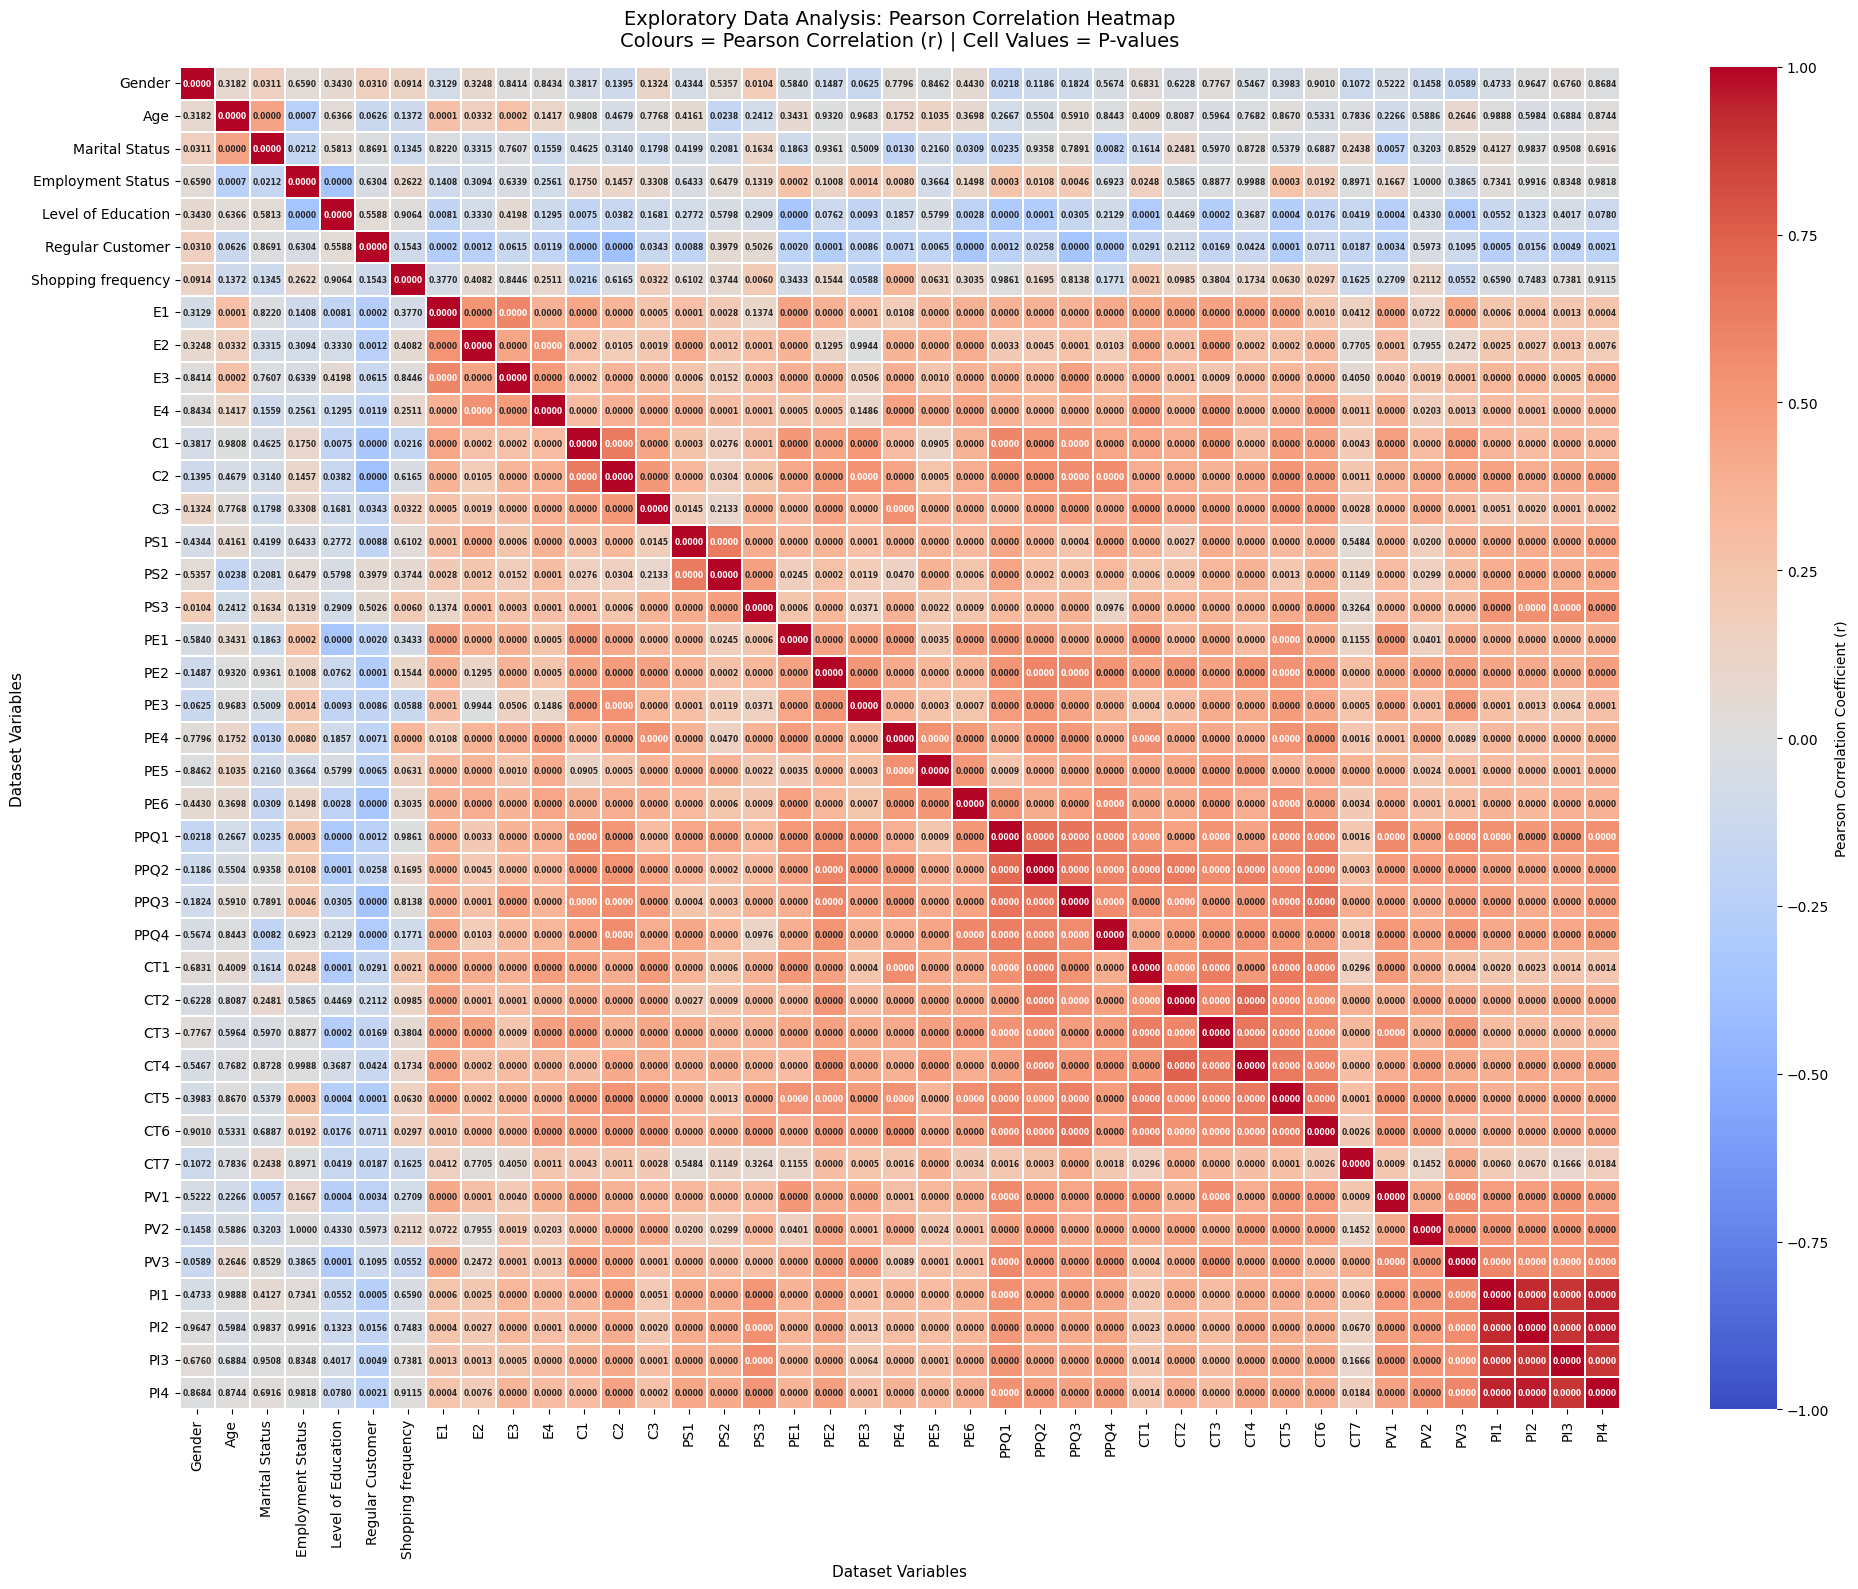

In [ ]:
plt.figure(figsize=(20, 16))

ax = sns.heatmap(
    r_vals,
    annot=p_annotations,
    fmt="",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.2,
    cbar_kws={
        "label": "Pearson Correlation Coefficient (r)"
    },
    annot_kws={
        "size": 5.5,
        "weight": "bold"
    }
)

plt.title(
    "Exploratory Data Analysis: Pearson Correlation Heatmap\n"
    "Colours = Pearson Correlation (r) | Cell Values = P-values",
    fontsize=14,
    pad=15
)

plt.xlabel("Dataset Variables", fontsize=11)
plt.ylabel("Dataset Variables", fontsize=11)

plt.tight_layout()
plt.show()


**3. Justification of Variable Selection**

i. Category Representation: Exactly one representative variable was selected from each of the 9 dataset categories (Level of Education, Regular Customer, E1, C2, PS1, PE2, PPQ1, CT5, and PI4) to cover all demographic, operational, and perceptual constructs without introducing redundancy.

**Heatmap Statistical Significance:**

Expectations (E1) and Convenience (C2): Selected because they show a statistically significant relationship on the Pearson correlation heatmap (p = 0.000001), establishing that initial store expectations directly align with perceived access convenience.

Convenience (C2) and Product Selection (PS1): Exhibited a p-value of 0.000002, proving that store accessibility directly influences how consumers view product variety and availability.

Product Selection (PS1), Store Performance (PE2), Price-to-Quality (PPQ1), Customer Trust (CT5), and Purchase Intention (PI4): Every sequential pairwise connection across these construct nodes yielded near-zero p-values (p < 0.000001) on the correlation heatmap. This confirms that physical store performance, price-quality evaluations, and trust act as statistically significant drivers of ultimate purchase intent.

Level of Education and Regular Customer: Selected from Demographics and Behavior because education provides a stable background metric with lower multicollinearity than age, while Regular Customer serves as the primary behavioral filter connecting consumer demographics to store perceptions.

ii. Mapping the Sequential Decision Chain: The analysis is expected to reveal how physical store attributes cascade through consumer perceptions—showing how store convenience (C2) and product selection (PS1) feed into operational store performance (PE2), which subsequently drives price-quality evaluation (PPQ1) and customer trust (CT5).

Identifying Direct versus Mediated Drivers: The Bayesian Network will quantify whether operational store performance directly influences repurchase decisions or if its impact is fully mediated through customer trust (CT5) and price-to-quality perception (PPQ1).

Evaluating Customer Retention Factors: The conditional probability tables are anticipated to show that high customer trust (CT5) and strong price-to-quality ratings (PPQ1) yield the highest conditional probabilities for repurchase intent (PI4), providing clear operational targets for subsistence retail strategy.

**The heatmap interpretation**

The colour shading represents the strength and direction of the Pearson correlation coefficient (r), ranging from negative correlations to positive correlations. Stronger colours indicate stronger linear relationships between variables, while colours closer to the centre indicate weaker correlations.

The numerical values inside each cell represent the p-values associated with the Pearson correlation. A p-value below 0.05 indicates that the observed correlation is statistically significant at the 5% significance level.

**My Observation**

Statistically significant relationships (p < 0.05):
The cleaned dataset shows several variable pairs with p-values below 0.05, indicating statistically significant linear relationships. These relationships are important because they provide evidence of an association between the corresponding variables and can be considered when identifying relevant connections for the Bayesian Network.

Non-significant relationships (p ≥ 0.05):
Variable pairs with p-values of 0.05 or higher do not provide sufficient statistical evidence of a linear relationship. These weaker relationships can therefore be treated with less importance when identifying potential dependencies between variables.

Effect of removing duplicates:
Duplicate observations were removed before calculating the correlations to prevent repeated records from disproportionately influencing the Pearson correlation and p-values. Therefore, the updated heatmap provides a more reliable representation of the relationships within the dataset.

In [ ]:
#Question 2: Creating and Comparing Bayesian Networks
#Install bnlearn
!pip install bnlearn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 36.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 201.5/201.5 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.6/145.6 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 82.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.6/84.6 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 8.1 MB/s eta 0:00:00
  Created wheel for semopy: filename=semopy-2.3.11-py3-none-any.whl size=1659767 sha256=8e5479875b25d83900a104463e52da366c3e6d765279257acb9f6f3e5744ad5b
  Stored in directory: /root/.cache/pip/wheels/44/73/aa/17ef39e69a62fdb1cbda5d9ebf8318f130b12107bf05cad7f0
Successfully built semopy


In [ ]:
#Import necessary libraries
import bnlearn as bn
import pandas as pd

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [ ]:
#load dataset
from google.colab import files
uploaded = files.upload()

Saving Subsistence Retail Consumer Data.xlsx to Subsistence Retail Consumer Data (1).xlsx


In [ ]:
# Read the Excel file
df = pd.read_excel("Subsistence Retail Consumer Data.xlsx")

# Record number of observations before removing duplicates
rows_before = len(df)

# Remove duplicate observations
df = df.drop_duplicates().reset_index(drop=True)

# Record number of observations after removing duplicates
rows_after = len(df)

print("Rows before removing duplicates:", rows_before)
print("Rows after removing duplicates:", rows_after)
print("Duplicates removed:", rows_before - rows_after)

Rows before removing duplicates: 281
Rows after removing duplicates: 188
Duplicates removed: 93


In [ ]:
# Check dimensions and list column headers
print("Data frame shape:", df.shape)
print("\nAvailable features:")
print(list(df.columns))

Data frame shape: (188, 41)

Available features:
['Gender', 'Age', 'Marital Status', 'Employment Status', 'Level of Education', 'Regular Customer', 'Shopping frequency', 'E1', 'E2', 'E3', 'E4', 'C1', 'C2', 'C3', 'PS1', 'PS2', 'PS3', 'PE1', 'PE2', 'PE3', 'PE4', 'PE5', 'PE6', 'PPQ1', 'PPQ2', 'PPQ3', 'PPQ4', 'CT1', 'CT2', 'CT3', 'CT4', 'CT5', 'CT6', 'CT7', 'PV1', 'PV2', 'PV3', 'PI1', 'PI2', 'PI3', 'PI4']


In [ ]:
# Map 1 selected variable from each of the 9 categories to clean abbreviations
selected_cols = {
    'Level of Education': 'UserEdu',  # 1. Demographics
    'Regular Customer': 'IsRegular',  # 2. Shopping Behavior
    'E1': 'Expectations',  # 3. Expectations (E)
    'C2': 'Convenience',  # 4. Convenience (C)
    'PS1': 'ProdSelection',  # 5. Product Selection (PS)
    'PE2': 'StorePerf',  # 6. Performance/Efficiency (PE)
    'PPQ1': 'PriceQuality',  # 7. Price & Product Quality (PPQ)
    'CT5': 'CustomerTrust',  # 8. Customer Trust/Satisfaction (CT)
    'PI4': 'BuyIntent',  # 9. Perceived Value & Purchase Intention (PV/PI)
}

# Select variables, rename them, and drop missing values
df_bn = df[list(selected_cols.keys())].rename(columns=selected_cols).dropna().reset_index(drop=True)

print("9 Variables used for Bayesian Network:")
print(df_bn.columns.tolist())
print("\nNumber of observations:", len(df_bn))
display(df_bn.head())

9 Variables used for Bayesian Network:
['UserEdu', 'IsRegular', 'Expectations', 'Convenience', 'ProdSelection', 'StorePerf', 'PriceQuality', 'CustomerTrust', 'BuyIntent']

Number of observations: 188


,UserEdu,IsRegular,Expectations,Convenience,ProdSelection,StorePerf,PriceQuality,CustomerTrust,BuyIntent
0,4,2,3,3,2,3,3,3,4
1,4,1,3,4,2,3,1,2,4
2,2,2,3,3,4,3,3,2,3
3,3,2,3,3,4,4,3,2,4
4,2,2,2,3,1,1,3,2,3


In [ ]:
# Define expert directional dependencies across all 9 categories
expert_edges = [
    ('UserEdu', 'IsRegular'),  # Demographics influence Shopping Behavior
    ('IsRegular', 'Expectations'),  # Shopping Behavior drives Expectations
    ('Expectations', 'Convenience'),  # Customer Expectations influence Perceived Convenience
    ('Convenience', 'ProdSelection'),  # Convenience influences Product Selection perception
    ('ProdSelection', 'StorePerf'),  # Product Selection affects Store Performance perception
    ('StorePerf', 'PriceQuality'),  # Store Performance influences Price-Quality evaluation
    ('PriceQuality', 'CustomerTrust'),  # Price-Quality perception builds Customer Trust
    ('CustomerTrust', 'BuyIntent'),  # Customer Trust directly drives Repurchase Intention
    ('IsRegular', 'CustomerTrust'),  # Patronage status directly influences overall Trust
]

# Create expert DAG
DAG_expert = bn.make_DAG(expert_edges)
print("9-Variable Expert DAG created successfully.")

[13-10-2026 08:56:27] [bnlearn] [INFO] Auto generate placeholders for the CPTs.
[13-10-2026 08:56:27] [bnlearn] [INFO] CPT for IsRegular:
[13-10-2026 08:56:28] [bnlearn] [INFO] CPT for Expectations:
[13-10-2026 08:56:28] [bnlearn] [INFO] CPT for Convenience:
[13-10-2026 08:56:28] [bnlearn] [INFO] CPT for ProdSelection:
[13-10-2026 08:56:28] [bnlearn] [INFO] CPT for StorePerf:
[13-10-2026 08:56:28] [bnlearn] [INFO] CPT for PriceQuality:
[13-10-2026 08:56:28] [bnlearn] [INFO] CPT for CustomerTrust:
[13-10-2026 08:56:28] [bnlearn] [INFO] CPT for BuyIntent:
[13-10-2026 08:56:28] [bnlearn] [INFO] CPT for UserEdu:
[13-10-2026 08:56:28] [bnlearn] [INFO] bayes DAG created.
[13-10-2026 08:56:28] [bnlearn] [INFO] [CPD > Update  ] >[Node IsRegular]
[13-10-2026 08:56:28] [bnlearn] [INFO] [CPD > Update  ] >[Node Expectations]
[13-10-2026 08:56:28] [bnlearn] [INFO] [CPD > Update  ] >[Node Convenience]
[13-10-2026 08:56:28] [bnlearn] [INFO] [CPD > Update  ] >[Node ProdSelection]
[13-10-2026 08:56:28]

+--------------+------------+------------+
| UserEdu      | UserEdu(0) | UserEdu(1) |
+--------------+------------+------------+
| IsRegular(0) | 0.5        | 0.5        |
+--------------+------------+------------+
| IsRegular(1) | 0.5        | 0.5        |
+--------------+------------+------------+
+-----------------+--------------+--------------+
| IsRegular       | IsRegular(0) | IsRegular(1) |
+-----------------+--------------+--------------+
| Expectations(0) | 0.5          | 0.5          |
+-----------------+--------------+--------------+
| Expectations(1) | 0.5          | 0.5          |
+-----------------+--------------+--------------+
+----------------+-----------------+-----------------+
| Expectations   | Expectations(0) | Expectations(1) |
+----------------+-----------------+-----------------+
| Convenience(0) | 0.5             | 0.5             |
+----------------+-----------------+-----------------+
| Convenience(1) | 0.5             | 0.5             |
+----------------+-

[13-10-2026 08:56:32] [bnlearn] [INFO] Set node properties.
[13-10-2026 08:56:32] [bnlearn] [INFO] Set edge properties.
[13-10-2026 08:56:32] [bnlearn] [INFO] Plot based on Bayesian model
[13-10-2026 08:56:32] [bnlearn] [INFO] Using hierarchical top-down layout (graphviz_layout_custom).
[13-10-2026 08:56:32] [bnlearn] [INFO] Existing coordinates from <pos> are used.


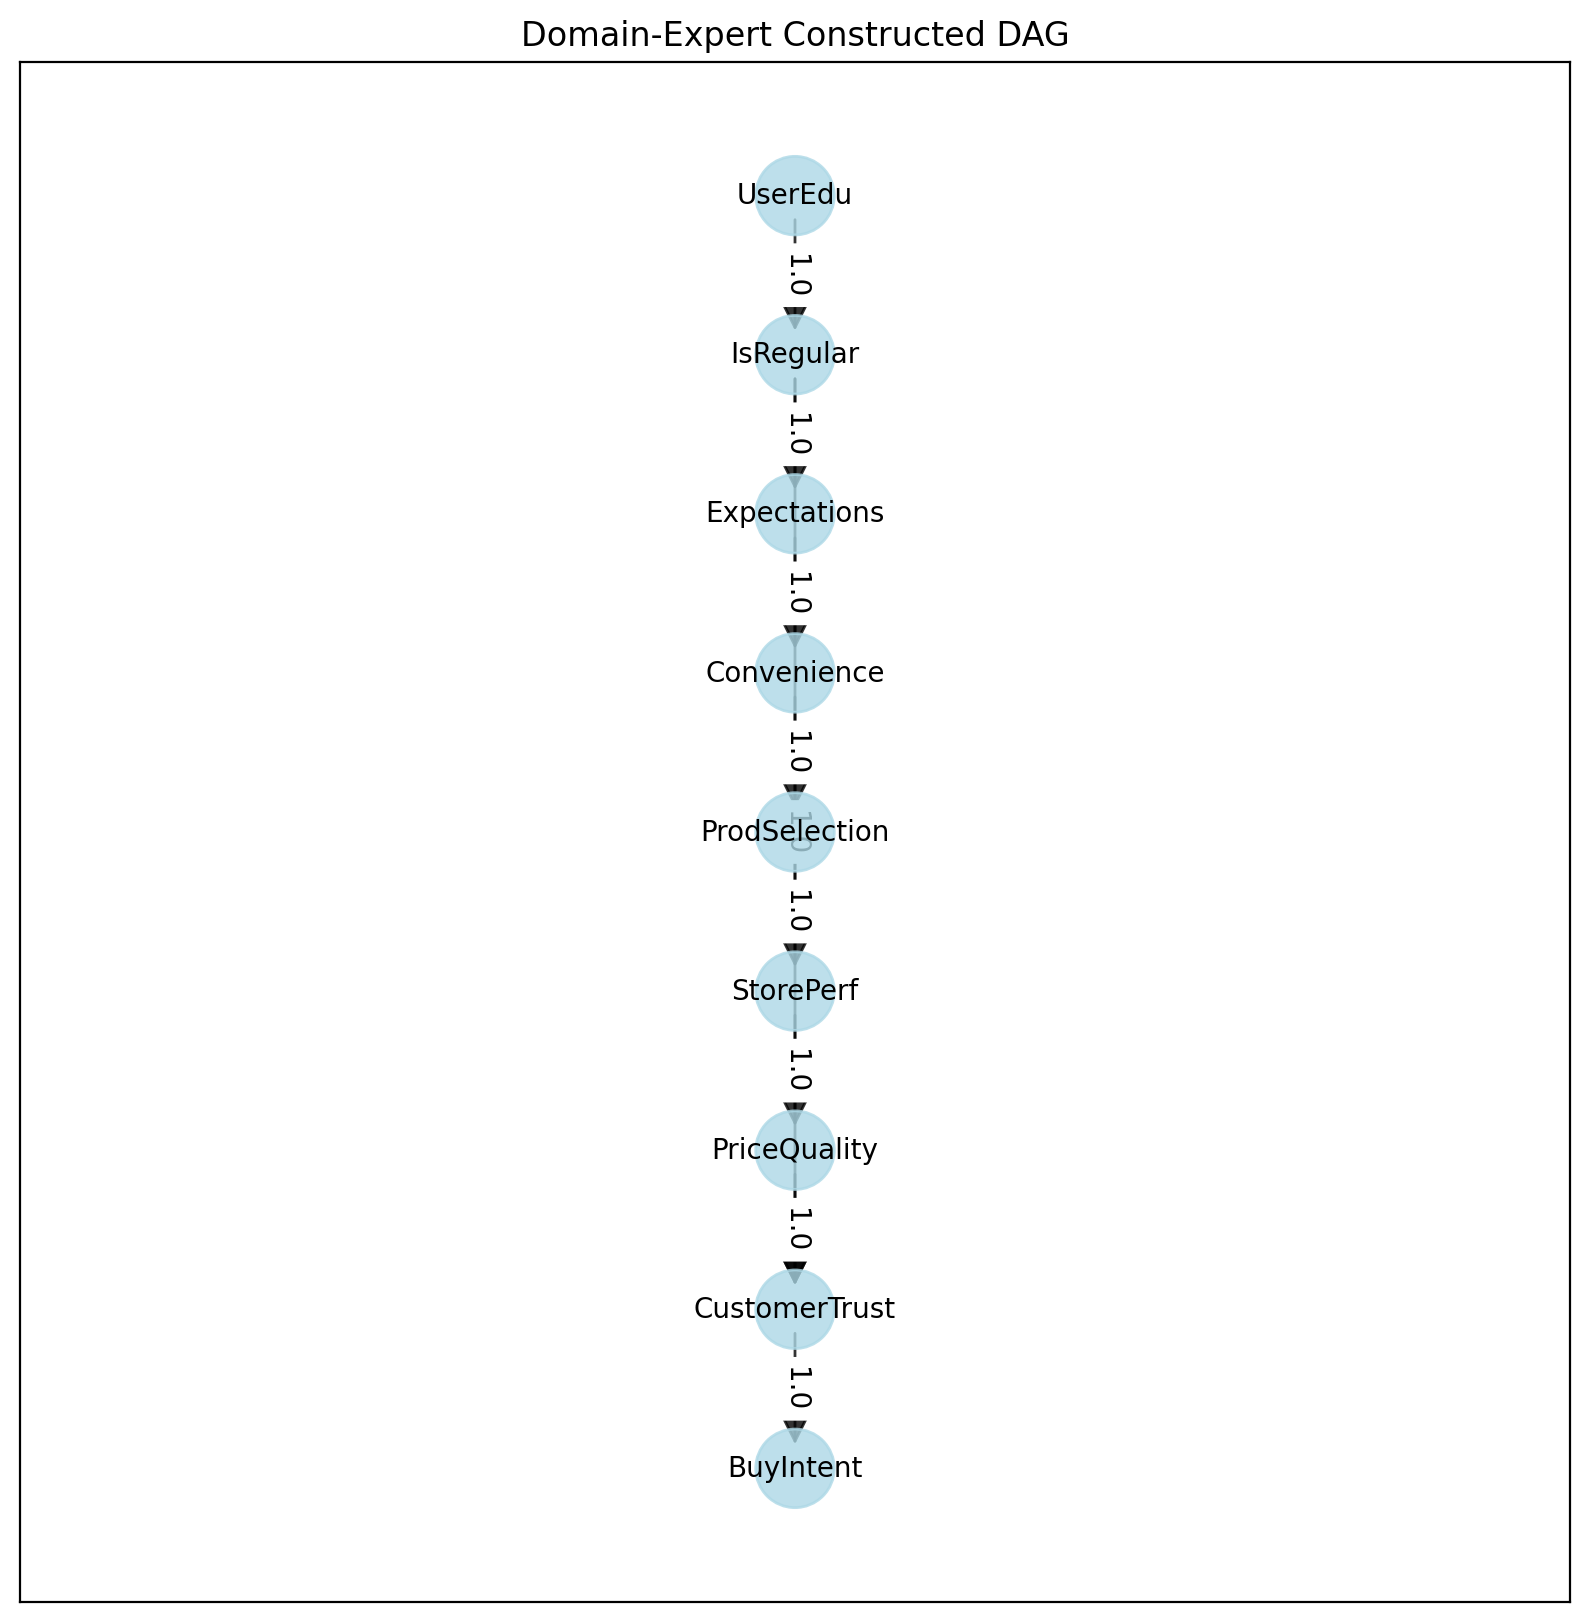

{'fig': <Figure size 2000x2000 with 1 Axes>,
 'ax': <Figure size 2000x2000 with 1 Axes>,
 'pos': {'UserEdu': array([0., 1.]),
  'IsRegular': array([0.  , 0.75]),
  'Expectations': array([0. , 0.5]),
  'Convenience': array([0.  , 0.25]),
  'ProdSelection': array([0., 0.]),
  'StorePerf': array([ 0.  , -0.25]),
  'PriceQuality': array([ 0. , -0.5]),
  'CustomerTrust': array([ 0.  , -0.75]),
  'BuyIntent': array([ 0., -1.])},
 'G': <networkx.classes.digraph.DiGraph at 0x7b19f2b7dfd0>,
 'node_properties': {'UserEdu': {'node_color': '#ADD8E6', 'node_size': 800},
  'IsRegular': {'node_color': '#ADD8E6', 'node_size': 800},
  'Expectations': {'node_color': '#ADD8E6', 'node_size': 800},
  'Convenience': {'node_color': '#ADD8E6', 'node_size': 800},
  'ProdSelection': {'node_color': '#ADD8E6', 'node_size': 800},
  'StorePerf': {'node_color': '#ADD8E6', 'node_size': 800},
  'PriceQuality': {'node_color': '#ADD8E6', 'node_size': 800},
  'CustomerTrust': {'node_color': '#ADD8E6', 'node_size': 800},


In [ ]:
# Graph the manual expert network

bn.plot(
    DAG_expert,
    title="Domain-Expert Constructed DAG"
)

In [ ]:
#2. Learning a DAG Structure from Data
# Learn DAG relationships using Hill-Climbing algorithm
dag_data_driven = bn.structure_learning.fit(
    df_bn,
    methodtype='hc',
    scoretype='bic'
)

print("DAG structure successfully extracted from deduplicated data.")

[13-10-2026 08:56:37] [bnlearn] [INFO] Set scoring type at [bic]
[13-10-2026 08:56:37] [bnlearn] [INFO] Computing best DAG using [hc]
[13-10-2026 08:56:37] [bnlearn] [INFO] Set scoring type at [bic]
[13-10-2026 08:56:38] [bnlearn] [INFO] Compute structure scores [k2, bic, bdeu, bds] for model comparison (higher is better).


DAG structure successfully extracted from deduplicated data.


[bnlearn] >Set node properties.
[bnlearn] >Set edge properties.
[bnlearn] >Plot based on Bayesian model


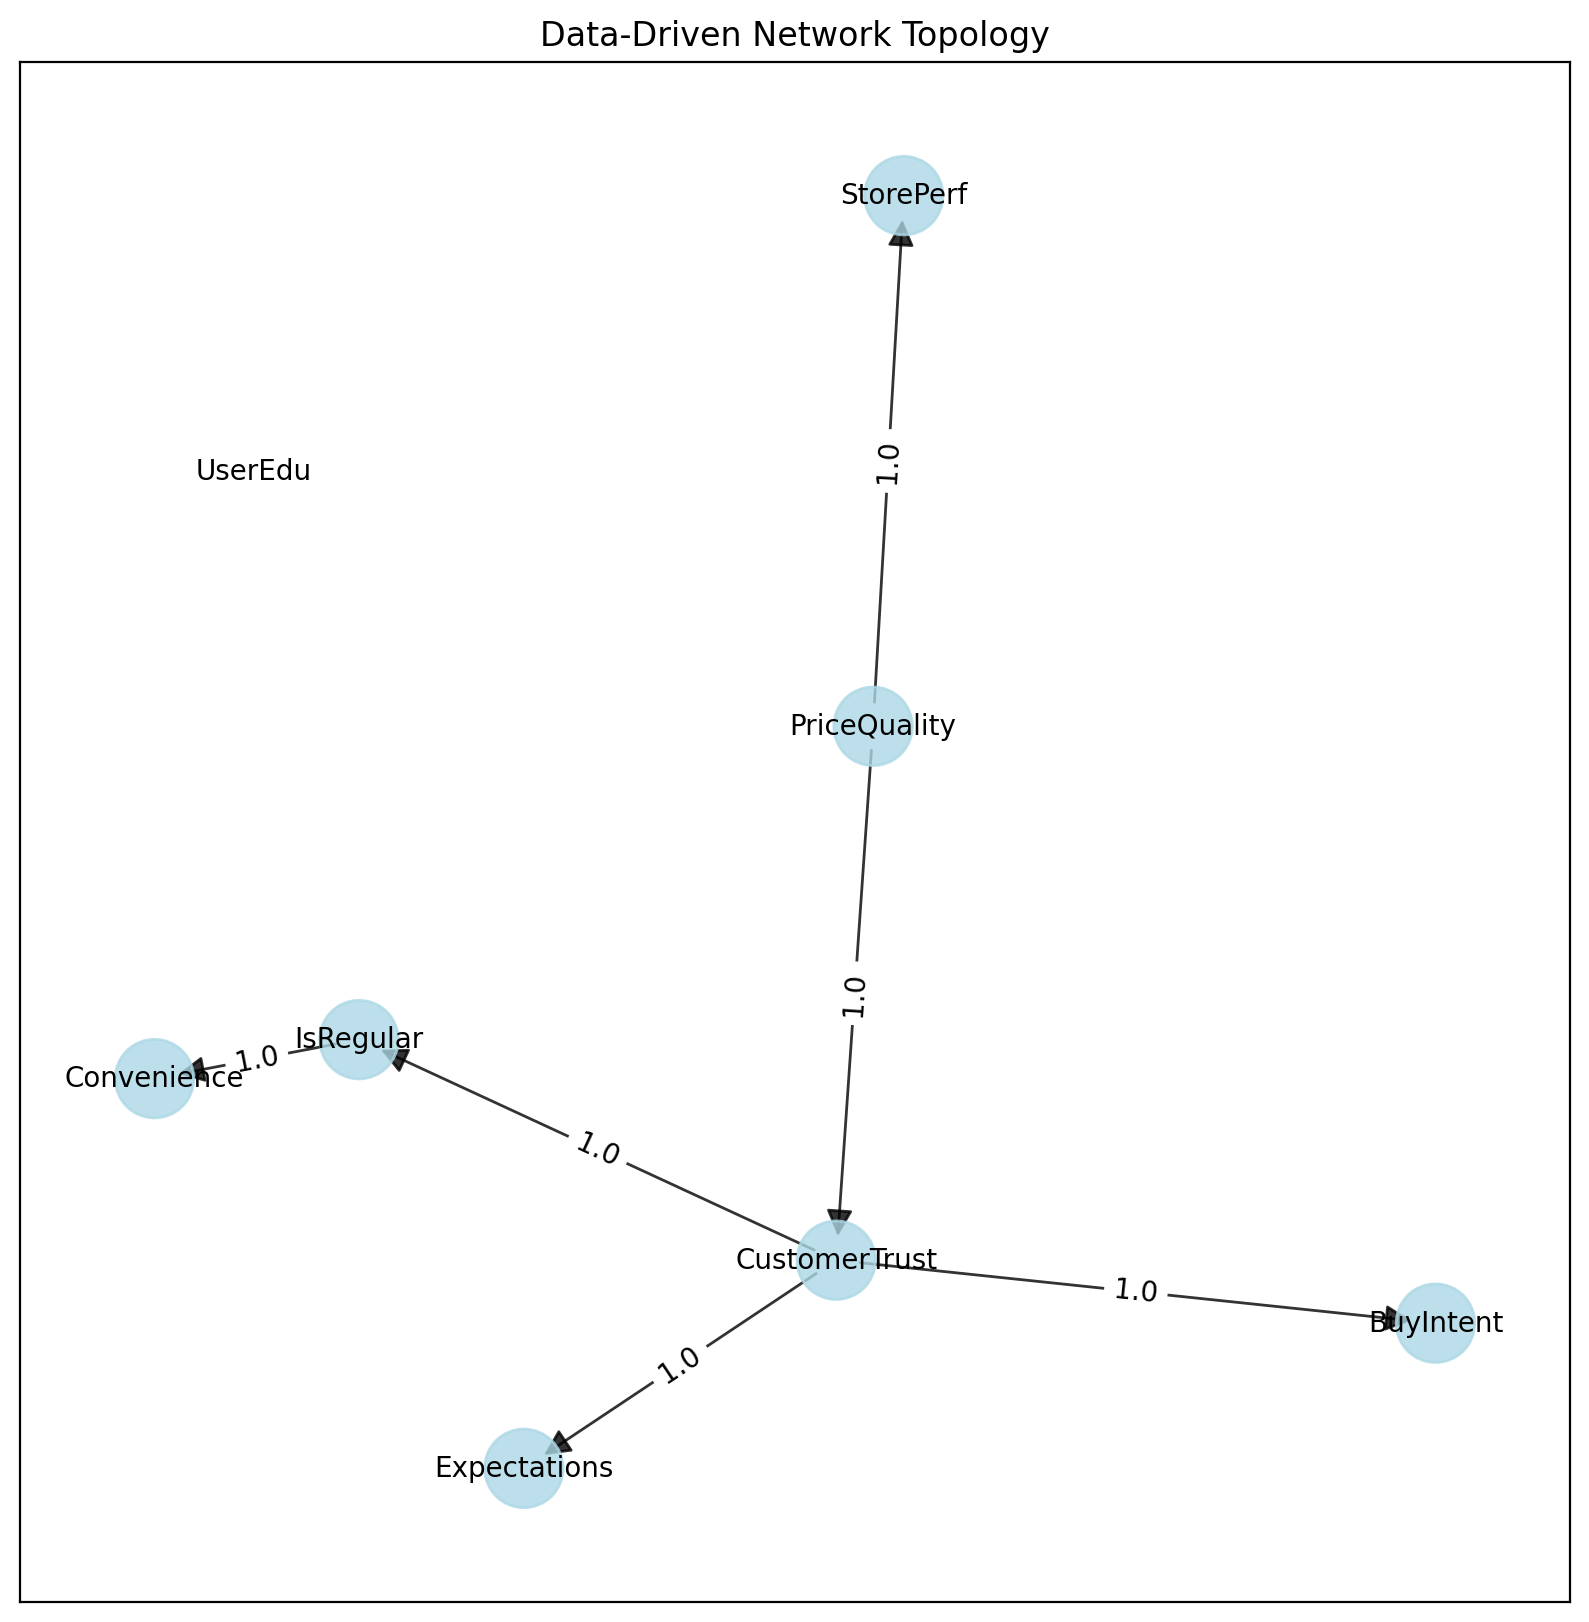

{'fig': <Figure size 2000x2000 with 1 Axes>,
 'ax': <Figure size 2000x2000 with 1 Axes>,
 'pos': {'UserEdu': array([-0.557324  ,  0.66925201]),
  'IsRegular': array([-0.42387768, -0.01165927]),
  'Expectations': array([-0.21440297, -0.52559911]),
  'Convenience': array([-0.68378937, -0.05842875]),
  'ProdSelection': array([ 0.25546374, -0.80980347]),
  'StorePerf': array([0.26826789, 1.        ]),
  'PriceQuality': array([0.22928476, 0.36389998]),
  'CustomerTrust': array([ 0.18240615, -0.27607529]),
  'BuyIntent': array([ 0.94397146, -0.3515861 ])},
 'G': <networkx.classes.digraph.DiGraph at 0x7b02637be990>,
 'node_properties': {'UserEdu': {'node_color': '#ADD8E6', 'node_size': 800},
  'IsRegular': {'node_color': '#ADD8E6', 'node_size': 800},
  'Expectations': {'node_color': '#ADD8E6', 'node_size': 800},
  'Convenience': {'node_color': '#ADD8E6', 'node_size': 800},
  'ProdSelection': {'node_color': '#ADD8E6', 'node_size': 800},
  'StorePerf': {'node_color': '#ADD8E6', 'node_size': 800

In [ ]:
# Graph the data-driven network
bn.plot(
    dag_data_driven,
    title="Data-Driven Network Topology"
)

[13-10-2026 08:56:40] [bnlearn] [INFO] Confusion matrix, without normalization
[13-10-2026 08:56:40] [bnlearn] [INFO] [[68  4]
 [ 7  2]]


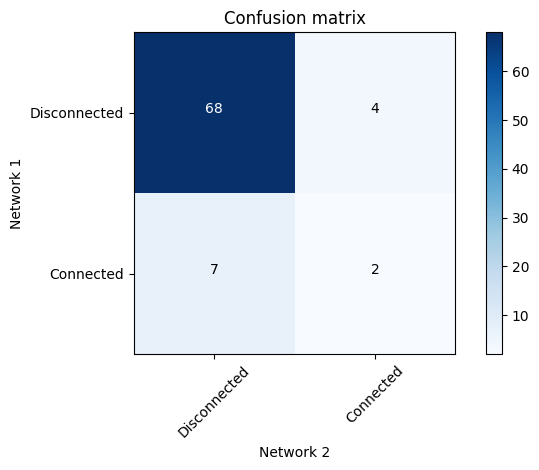

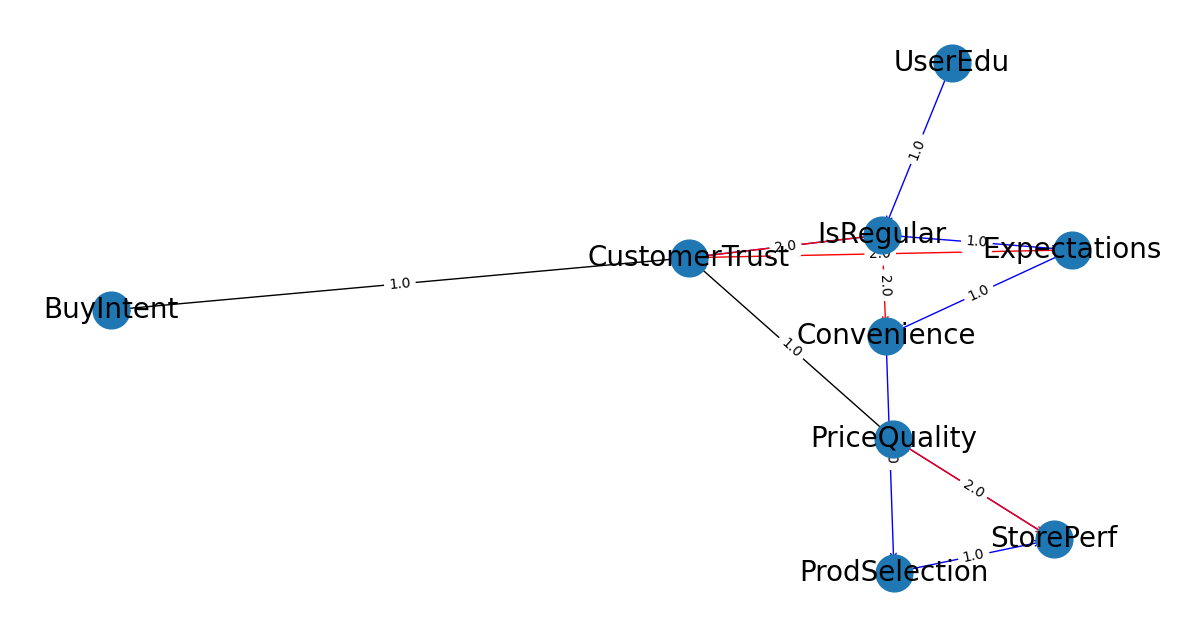

--- Structural Comparison Scores ---


array([[68,  4],
       [ 7,  2]])

In [ ]:
#3.Comparison of DAGs
# Compare structural discrepancies between expert and data-driven models

comp_metrics, structural_diff = bn.compare_networks(
    DAG_expert,
    dag_data_driven
)

print("--- Structural Comparison Scores ---")
display(comp_metrics)

In [ ]:
print("--- Structural Adjacency Matrix ---")
display(structural_diff)

--- Structural Adjacency Matrix ---


target,UserEdu,IsRegular,Expectations,Convenience,ProdSelection,StorePerf,PriceQuality,CustomerTrust,BuyIntent
source,,,,,,,,,
UserEdu,0,-1,0,0,0,0,0,0,0
IsRegular,0,0,-1,2,0,0,0,-1,0
Expectations,0,0,0,-1,0,0,0,0,0
Convenience,0,0,0,0,-1,0,0,0,0
ProdSelection,0,0,0,0,0,-1,0,0,0
StorePerf,0,0,0,0,0,0,-1,0,0
PriceQuality,0,0,0,0,0,2,0,1,0
CustomerTrust,0,2,2,0,0,0,0,0,1
BuyIntent,0,0,0,0,0,0,0,0,0


In [ ]:
# Fit conditional probability distributions (CPTs)
# using the expert DAG and deduplicated data

fitted_bn = bn.parameter_learning.fit(
    DAG_expert,
    df_bn
)

# Output conditional probability distributions for every node
for target_node in fitted_bn['model'].nodes():
    print(f"\n--- Conditional Probability Table: {target_node} ---")
    print(fitted_bn['model'].get_cpds(target_node))

[13-10-2026 08:57:54] [bnlearn] [INFO] methodtype="auto" -> [bayes] for discrete data
[13-10-2026 08:57:54] [bnlearn] [INFO] Parameter learning> Computing parameters using [bayes]
[13-10-2026 08:58:03] [bnlearn] [INFO] CPD of IsRegular:
[13-10-2026 08:58:03] [bnlearn] [INFO] CPD of Expectations:
[13-10-2026 08:58:03] [bnlearn] [INFO] CPD of Convenience:
[13-10-2026 08:58:03] [bnlearn] [INFO] CPD of ProdSelection:
[13-10-2026 08:58:03] [bnlearn] [INFO] CPD of StorePerf:
[13-10-2026 08:58:03] [bnlearn] [INFO] CPD of PriceQuality:
[13-10-2026 08:58:03] [bnlearn] [INFO] CPD of CustomerTrust:
[13-10-2026 08:58:03] [bnlearn] [INFO] CPD of BuyIntent:
[13-10-2026 08:58:03] [bnlearn] [INFO] CPD of UserEdu:
[13-10-2026 08:58:03] [bnlearn] [INFO] Compute structure scores [k2, bic, bdeu, bds] for model comparison (higher is better).


+--------------+--------------------+-----+---------------------+
| UserEdu      | UserEdu(1)         | ... | UserEdu(5)          |
+--------------+--------------------+-----+---------------------+
| IsRegular(1) | 0.5272727272727272 | ... | 0.504950495049505   |
+--------------+--------------------+-----+---------------------+
| IsRegular(2) | 0.4727272727272727 | ... | 0.49504950495049505 |
+--------------+--------------------+-----+---------------------+
+-----------------+---------------------+---------------------+
| IsRegular       | IsRegular(1)        | IsRegular(2)        |
+-----------------+---------------------+---------------------+
| Expectations(1) | 0.16666666666666666 | 0.19288389513108614 |
+-----------------+---------------------+---------------------+
| Expectations(2) | 0.1834862385321101  | 0.20411985018726592 |
+-----------------+---------------------+---------------------+
| Expectations(3) | 0.20030581039755352 | 0.2153558052434457  |
+-----------------+-------

[bnlearn] >Set node properties.
[bnlearn] >Set edge properties.
[bnlearn] >Plot based on Bayesian model


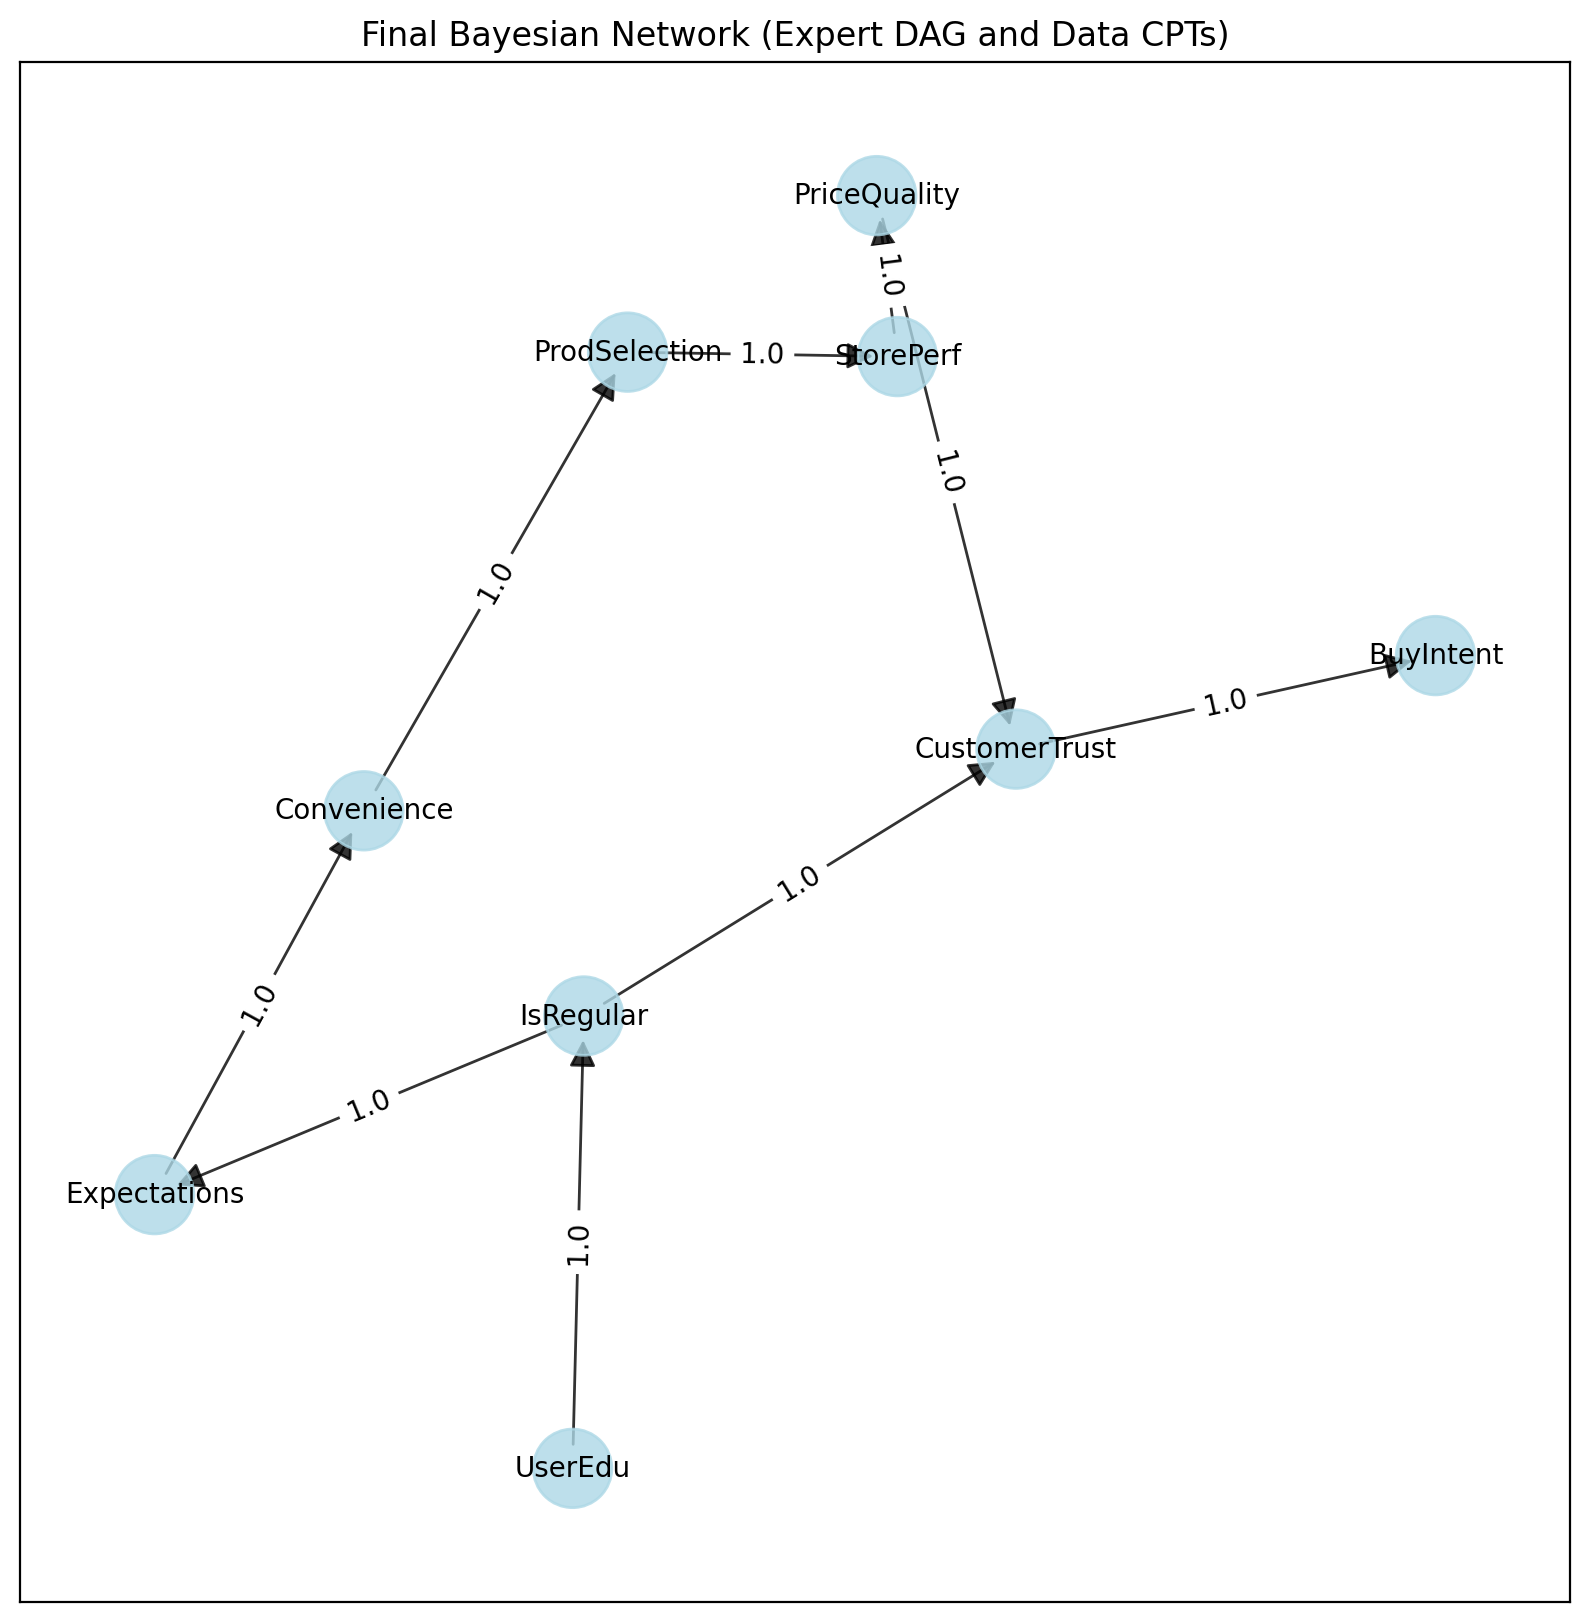

{'fig': <Figure size 2000x2000 with 1 Axes>,
 'ax': <Figure size 2000x2000 with 1 Axes>,
 'pos': {'UserEdu': array([-0.21506386, -0.50638682]),
  'IsRegular': array([-0.19932678, -0.18508742]),
  'Expectations': array([-0.80372045, -0.31194812]),
  'Convenience': array([-0.50895919, -0.03932282]),
  'ProdSelection': array([-0.1375856 ,  0.28644926]),
  'StorePerf': array([0.24219434, 0.28329047]),
  'PriceQuality': array([0.21320688, 0.39760844]),
  'CustomerTrust': array([0.40925467, 0.00448673]),
  'BuyIntent': array([1.        , 0.07091026])},
 'G': <networkx.classes.digraph.DiGraph at 0x7b02a9f4d6e0>,
 'node_properties': {'UserEdu': {'node_color': '#ADD8E6', 'node_size': 800},
  'IsRegular': {'node_color': '#ADD8E6', 'node_size': 800},
  'Expectations': {'node_color': '#ADD8E6', 'node_size': 800},
  'Convenience': {'node_color': '#ADD8E6', 'node_size': 800},
  'ProdSelection': {'node_color': '#ADD8E6', 'node_size': 800},
  'StorePerf': {'node_color': '#ADD8E6', 'node_size': 800},
 

In [ ]:
# Display final parameter-fitted BN
bn.plot(
    fitted_bn,
    title="Final Bayesian Network (Expert DAG and Data CPTs)"
)

In [ ]:
# Question 3: Inference and Interpretation
# Check possible discrete values for each of the 9 variables
for column in df_bn.columns:
    print(f"\n{column}:")
    print(sorted(df_bn[column].unique()))


UserEdu:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

IsRegular:
[np.int64(1), np.int64(2)]

Expectations:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Convenience:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

ProdSelection:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

StorePerf:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

PriceQuality:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

CustomerTrust:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

BuyIntent:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [ ]:
# Check the nodes and learned CPTs in the final Bayesian Network

print("BN nodes:")
print(list(fitted_bn['model'].nodes()))

print("\nLearned CPTs:")

for node in fitted_bn['model'].nodes():
    print(f"\n{'='*50}")
    print(f"CPT: {node}")
    print(f"{'='*50}")
    print(fitted_bn['model'].get_cpds(node))

BN nodes:
['UserEdu', 'IsRegular', 'Expectations', 'Convenience', 'ProdSelection', 'StorePerf', 'PriceQuality', 'CustomerTrust', 'BuyIntent']

Learned CPTs:

CPT: UserEdu
+------------+----------+
| UserEdu(1) | 0.185185 |
+------------+----------+
| UserEdu(2) | 0.239899 |
+------------+----------+
| UserEdu(3) | 0.212963 |
+------------+----------+
| UserEdu(4) | 0.191919 |
+------------+----------+
| UserEdu(5) | 0.170034 |
+------------+----------+

CPT: IsRegular
+--------------+--------------------+-----+---------------------+
| UserEdu      | UserEdu(1)         | ... | UserEdu(5)          |
+--------------+--------------------+-----+---------------------+
| IsRegular(1) | 0.5272727272727272 | ... | 0.504950495049505   |
+--------------+--------------------+-----+---------------------+
| IsRegular(2) | 0.4727272727272727 | ... | 0.49504950495049505 |
+--------------+--------------------+-----+---------------------+

CPT: Expectations
+-----------------+---------------------+-----

In [ ]:
# Create inference engine

from pgmpy.inference import VariableElimination

model = fitted_bn['model']

inference = VariableElimination(model)

print("Inference engine created successfully.")

Inference engine created successfully.


**2 Interpretation of Inference Results**

**Inference 1:** Customer Trust and Purchase Intention

When maximum Customer Trust is observed (CustomerTrust = 5), the conditional probability distribution shows that the highest purchase intention outcome (BuyIntent = 5) dominates at 64.44%, with BuyIntent = 4 reaching 17.78%, BuyIntent = 3 at 13.33%, and BuyIntent = 2 at 4.44%. This indicates that customer trust acts as an essential, high-impact direct antecedent to consumer purchase decisions in subsistence retail environments. When trust is firmly established, customer hesitation drops sharply, and consumers overwhelmingly shift toward definite repurchase behavior. Retail strategies must prioritize transparent pricing, reliable stock, and fair policies to build consumer trust.

**Inference 2:** Price-to-Quality Perception and Purchase Intention

When consumers perceive top-tier price-to-quality value (PriceQuality = 5), the probability of top repurchase intent (BuyIntent = 5) reaches 56.82%, while BuyIntent = 4 registers at 31.82% and BuyIntent = 3 accounts for 11.36%. Price-to-quality alignment serves as a critical purchase catalyst in low-income or price-sensitive consumer segments. Because consumers in subsistence markets operate under budget constraints, perceiving that a product provides maximum utility per unit of currency strongly drives purchasing behavior. Retailers should focus on highlighting product value propositions and maintaining competitive basket pricing.

**Inference 3:** Operational Store Performance and Purchase Intention

Under conditions of high operational store performance (StorePerf = 5), BuyIntent = 5 achieves a 50.00% probability, followed by BuyIntent = 4 at 36.00%, BuyIntent = 3 at 12.00%, and BuyIntent = 2 at 2.00%. Efficient store operations (such as fast checkout speed, helpful staff, and clean store navigation) create a strong baseline for customer retention. However, store performance alone yields a slightly lower peak repurchase probability than direct trust (64.44%), proving that operational efficiency functions primarily as an operational enabler rather than a final emotional closing factor for repurchase decisions.


**Inference 4:** Combined Customer Trust and Price Quality

When maximum Customer Trust and Price-to-Quality perceptions are jointly present (CustomerTrust = 5, PriceQuality = 5), the probability of top purchase intent (BuyIntent = 5) climbs significantly to 72.00%, with BuyIntent = 4 at 16.00% and BuyIntent = 3 at 12.00%. This joint inference highlights a powerful synergistic effect. When low-income consumers experience both high trust in the retailer and high perceived product quality relative to price, uncertainty is effectively removed. Jointly managing pricing transparency and trust-building initiatives produces a stronger conversion rate than focusing on operational parameters in isolation.

**Inference 5:** Combined Store Convenience and Product Selection

When store convenience and product variety are jointly maximized (Convenience = 5, ProdSelection = 5), the probability of top purchase intent (BuyIntent = 5) stands at 50.00%, while BuyIntent = 4 reaches 37.50% and BuyIntent = 3 accounts for 12.50%. Convenient store access paired with wide product availability successfully drives strong positive purchase intentions (BuyIntent = 4 or 5 combined probability of 87.50%). These upstream operational variables function as necessary baseline drivers that motivate store visits and feed downstream trust and value evaluation.

**Inference 6:** Demographic Profile , Patronage , and Trust

Observing a demographic segment of educated consumers (UserEdu = 3) who are regular patrons (IsRegular = 1) and express maximum trust (CustomerTrust = 5) yields an 80.00% probability for maximum repurchase intent (BuyIntent = 5) and 20.00% for BuyIntent = 3. Incorporating demographic and behavioral filters demonstrates that regular, educated customers who trust the store exhibit the highest conditional repurchase commitment in the model. This finding emphasizes the value of customer retention programs aimed at converting casual visitors into regular patrons through trust-building policies.

In [ ]:
# Test one inference with updated variable name ('Expectations' or 'Convenience')
result = inference.query(
    variables=['BuyIntent'],
    evidence={'Expectations': 5}
)

print(result)

+--------------+------------------+
| BuyIntent    |   phi(BuyIntent) |
+==============+==================+
| BuyIntent(1) |           0.1726 |
+--------------+------------------+
| BuyIntent(2) |           0.1818 |
+--------------+------------------+
| BuyIntent(3) |           0.1995 |
+--------------+------------------+
| BuyIntent(4) |           0.2332 |
+--------------+------------------+
| BuyIntent(5) |           0.2129 |
+--------------+------------------+


In [ ]:
# Test 6 inferences using updated 9-variable names
inferences = {
    "Inference 1: Customer Trust → Buy Intent": {
        'CustomerTrust': 5
    },

    "Inference 2: Price Quality → Buy Intent": {
        'PriceQuality': 5
    },

    "Inference 3: Store Performance → Buy Intent": {
        'StorePerf': 5
    },

    "Inference 4: Customer Trust + Price Quality → Buy Intent": {
        'CustomerTrust': 5,
        'PriceQuality': 5
    },

    "Inference 5: Convenience + Product Selection → Buy Intent": {
        'Convenience': 5,
        'ProdSelection': 5
    },

    "Inference 6: Education Level + Regular Customer Status + Customer Trust → Buy Intent": {
        'UserEdu': 3,
        'IsRegular': 1,
        'CustomerTrust': 5
    }
}

for name, evidence in inferences.items():
    print("\n" + "=" * 70)
    print(name)
    print("Evidence:", evidence)
    print("=" * 70)

    result = inference.query(
        variables=['BuyIntent'],
        evidence=evidence
    )

    print(result)


Inference 1: Customer Trust → Buy Intent
Evidence: {'CustomerTrust': 5}
+--------------+------------------+
| BuyIntent    |   phi(BuyIntent) |
+==============+==================+
| BuyIntent(1) |           0.1633 |
+--------------+------------------+
| BuyIntent(2) |           0.1714 |
+--------------+------------------+
| BuyIntent(3) |           0.1878 |
+--------------+------------------+
| BuyIntent(4) |           0.1959 |
+--------------+------------------+
| BuyIntent(5) |           0.2816 |
+--------------+------------------+

Inference 2: Price Quality → Buy Intent
Evidence: {'PriceQuality': 5}
+--------------+------------------+
| BuyIntent    |   phi(BuyIntent) |
+==============+==================+
| BuyIntent(1) |           0.1722 |
+--------------+------------------+
| BuyIntent(2) |           0.1803 |
+--------------+------------------+
| BuyIntent(3) |           0.1980 |
+--------------+------------------+
| BuyIntent(4) |           0.2304 |
+--------------+------------